# 23CSE301 — Machine Learning Capstone Project
## Clustering Track — Review 2 

**Dataset:** `online_retail_II.xlsx` — UCI *Online Retail II*, all transactions of a UK-based online gift-ware retailer between 01-Dec-2009 and 09-Dec-2011 (two worksheets, ~1.07 million rows).

**Problem statement:** The dataset has **no labels**. We segment the retailer's *customers* into natural groups based on their purchasing behaviour (a Recency / Frequency / Monetary style customer profile) so that a business could treat each group differently (retention, upselling, win-back campaigns).

**Algorithms (required):**
1. K-Means Clustering — Elbow curve to choose *k*
2. Agglomerative Hierarchical Clustering — Dendrogram + comparison of linkage strategies

**Metrics (all mandatory, reported for every algorithm):** Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index.

**Visualisation:** PCA (2 components) scatter for every algorithm, t-SNE for at least one.

**Notebook map**
| Section | Content |
|---|---|
| 1 | Setup & helper functions |
| 2 | Data loading & audit |
| 3 | Data cleaning |
| 4 | Feature engineering (customer-level table) |
| 5 | EDA with commentary |
| 6 | Preprocessing (outlier treatment, log-transform, scaling) |
| 7 | K-Means (Elbow, silhouette sweep, final model) |
| 8 | Agglomerative clustering (Dendrogram, linkage comparison, final model) |
| 9 | Evaluation metrics — consolidated table |
| 10 | Cluster visualisation (PCA for all, t-SNE) |
| 11 | Cluster profiling & business interpretation |
| 12 | Conclusion |

`random_state = 42` is used everywhere for reproducibility.


---
## 1. Setup & Helper Functions

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import (silhouette_score, davies_bouldin_score,
                             calinski_harabasz_score, adjusted_rand_score)
from scipy.cluster.hierarchy import linkage, dendrogram

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Colour-blind friendly palette (recommended in the guidelines)
PALETTE = sns.color_palette("colorblind")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")


**Helper functions.** Small reusable functions keep the notebook modular (rubric C1): one computes the three clustering metrics, one draws a PCA scatter, one profiles clusters.

In [2]:
def evaluate_clustering(X, labels, name):
    """Return the three mandatory internal validity metrics for one clustering.

    - Silhouette Score        : higher is better  (range -1 .. 1)
    - Davies-Bouldin Index    : LOWER is better   (0 is the best)
    - Calinski-Harabasz Index : higher is better
    Cluster sizes are included because a high score can come from a degenerate
    partition (e.g. one giant cluster + a few singletons) - always read both together.
    """
    return {
        "Algorithm": name,
        "Clusters": len(np.unique(labels)),
        "Silhouette": silhouette_score(X, labels),
        "Davies-Bouldin": davies_bouldin_score(X, labels),
        "Calinski-Harabasz": calinski_harabasz_score(X, labels),
        "Smallest cluster": int(pd.Series(labels).value_counts().min()),
        "Largest cluster": int(pd.Series(labels).value_counts().max()),
    }


def plot_embedding(coords, labels, title, xlabel, ylabel, ax=None):
    """Scatter a 2-D embedding (PCA or t-SNE), colour-coded by cluster label."""
    if ax is None:
        _, ax = plt.subplots(figsize=(7, 5.5))
    for i, c in enumerate(np.unique(labels)):
        m = labels == c
        ax.scatter(coords[m, 0], coords[m, 1], s=10, alpha=0.6,
                   color=PALETTE[i % len(PALETTE)], label=f"Cluster {c}")
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.legend(markerscale=2, fontsize=8)
    return ax


---
## 2. Data Loading & Audit

The workbook has **two worksheets** (2009-10 and 2010-11). Reading `.xlsx` with `openpyxl` is slow (a few minutes) — this is normal. The file is expected at `../data/online_retail_II.xlsx` (repository structure from the guidelines).


In [3]:
DATA_PATH = "../data/online_retail_II.xlsx"

# sheet_name=None -> dict of all worksheets; we stack them into a single table
sheets = pd.read_excel(DATA_PATH, sheet_name=None, engine="openpyxl")
for name, sheet in sheets.items():
    print(f"Sheet '{name}': {sheet.shape}")

raw = pd.concat(sheets.values(), ignore_index=True)
print("\nCombined shape:", raw.shape)


Sheet 'Year 2009-2010': (525461, 8)
Sheet 'Year 2010-2011': (541910, 8)

Combined shape: (1067371, 8)


In [4]:
print("Data types:")
print(raw.dtypes)
print()
raw.head()


Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
dtype: object



,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.950,"13,085.000",United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.750,"13,085.000",United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.100,"13,085.000",United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.250,"13,085.000",United Kingdom


In [5]:
# Missing-value audit
missing = pd.DataFrame({
    "missing_count": raw.isnull().sum(),
    "missing_pct": (raw.isnull().sum() / len(raw) * 100).round(2)
})
print(missing)

print("\nExact duplicate rows:", raw.duplicated().sum())
print("Date range:", raw["InvoiceDate"].min(), "->", raw["InvoiceDate"].max())
print("Unique customers (non-null IDs):", raw["Customer ID"].nunique())
print("Unique products (StockCode):", raw["StockCode"].nunique())
print("Countries:", raw["Country"].nunique())
print("Cancelled-invoice rows (Invoice starts with 'C'):",
      raw["Invoice"].astype(str).str.startswith("C").sum())
print("Rows with Quantity <= 0:", (raw["Quantity"] <= 0).sum(),
      "| Rows with Price <= 0:", (raw["Price"] <= 0).sum())


             missing_count  missing_pct
Invoice                  0        0.000
StockCode                0        0.000
Description           4382        0.410
Quantity                 0        0.000
InvoiceDate              0        0.000
Price                    0        0.000
Customer ID         243007       22.770
Country                  0        0.000

Exact duplicate rows: 34335
Date range: 2009-12-01 07:45:00 -> 2011-12-09 12:50:00
Unique customers (non-null IDs): 5942
Unique products (StockCode): 5305
Countries: 43
Cancelled-invoice rows (Invoice starts with 'C'): 19494
Rows with Quantity <= 0: 22950 | Rows with Price <= 0: 6207


**Observations.**
- Roughly 23% of the rows have **no `Customer ID`**. A customer-level segmentation cannot be built without an ID, so these must be dropped.
- There are tens of thousands of **exact duplicate rows**. The two worksheets also overlap for part of December 2010, so some duplication comes from that overlap.
- **Cancellations** (invoice numbers beginning with `C`, negative quantities) and **non-positive prices** exist — they are returns/adjustments, not purchases.
- `StockCode` also contains non-product codes (postage `POST`, `BANK CHARGES`, `M` for manual entries, gift vouchers …).
- There is **no target/label column**: this is purely unsupervised, so the "target distribution" requirement is replaced by a look at the distribution of customer-level behaviour in Section 5.


---
## 3. Data Cleaning

Cancellation behaviour is itself informative (a customer who returns a lot behaves differently), so we first **extract the per-customer cancellation count** from the raw data, and only then remove cancelled rows from the purchase table.

Cleaning steps (each logged so the effect is transparent):
1. Drop rows without `Customer ID` (cannot be attributed to a customer).
2. Drop exact duplicates (includes the overlap between the two worksheets).
3. Drop cancelled invoices (`Invoice` starting with `C`).
4. Drop rows with `Quantity <= 0` or `Price <= 0` (returns, adjustments, free/test items).
5. Keep only genuine product lines — `StockCode` beginning with 5 digits. This removes `POST`, `M`, `D`, `BANK CHARGES`, `AMAZONFEE`, gift vouchers and similar non-product entries that would distort spending.


In [6]:
df = raw.copy()
df["Invoice"] = df["Invoice"].astype(str)
df["StockCode"] = df["StockCode"].astype(str)

# --- Extract cancellations per customer BEFORE they are removed ---
cancelled = df[df["Invoice"].str.startswith("C") & df["Customer ID"].notna()]
cancel_counts = cancelled.groupby("Customer ID")["Invoice"].nunique().rename("CancelledInvoices")

cleaning_log = [("Raw rows", len(df))]

df = df.dropna(subset=["Customer ID"]);                    cleaning_log.append(("After dropping missing Customer ID", len(df)))
df = df.drop_duplicates();                                 cleaning_log.append(("After dropping duplicates", len(df)))
df = df[~df["Invoice"].str.startswith("C")];               cleaning_log.append(("After dropping cancelled invoices", len(df)))
df = df[(df["Quantity"] > 0) & (df["Price"] > 0)];         cleaning_log.append(("After dropping Quantity<=0 / Price<=0", len(df)))
df = df[df["StockCode"].str.match(r"^\d{5}")];             cleaning_log.append(("After keeping real product StockCodes", len(df)))

df["Customer ID"] = df["Customer ID"].astype(int)
df = df.reset_index(drop=True)

log_df = pd.DataFrame(cleaning_log, columns=["Step", "Rows remaining"])
log_df["Removed in step"] = (-log_df["Rows remaining"].diff()).fillna(0).astype(int)
log_df["Rows remaining"] = log_df["Rows remaining"].astype(int)
log_df


,Step,Rows remaining,Removed in step
0,Raw rows,1067371,0
1,After dropping missing Customer ID,824364,243007
2,After dropping duplicates,797885,26479
3,After dropping cancelled invoices,779495,18390
4,After dropping Quantity<=0 / Price<=0,779425,70
5,After keeping real product StockCodes,776577,2848


**Justification.** Instead of imputing a missing `Customer ID` (which would fabricate customers), we drop those rows — they cannot contribute to a customer segmentation. After cleaning, every remaining row is a genuine positive-quantity, positive-price product purchase attributed to a known customer.


---
## 4. Feature Engineering — Customer-level Table

Clustering needs **one row per customer**. We aggregate the transaction table into behavioural features. The classic **RFM** trio is extended with a few extra features:

| Feature | Definition | Why it may help clustering |
|---|---|---|
| `Recency` | Days from the customer's last purchase to the snapshot date (day after the last transaction in the data) | Separates active customers from lapsed ones |
| `Frequency` | Number of distinct invoices | Separates one-off buyers from loyal repeat buyers |
| `Monetary` | Total spend (Quantity × Price) | Separates high-value from low-value customers |
| `AvgOrderValue` | Monetary / Frequency | Distinguishes big-basket buyers from small-basket buyers even at equal frequency |
| `UniqueProducts` | Distinct `StockCode`s bought | Captures breadth of interest (wholesalers vs. casual gift buyers) |
| `TenureDays` | Days between first and last purchase | Captures how long the customer has been active |
| `CancelRate` | Cancelled invoices / (invoices + cancelled invoices) | Captures return behaviour |
| `TotalQuantity` | Total items bought | Kept for EDA only (almost redundant with `Monetary`) |


In [7]:
df["TotalPrice"] = df["Quantity"] * df["Price"]

# Snapshot date = one day after the last transaction, so Recency is always >= 1
snapshot_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)
print("Snapshot date:", snapshot_date)

g = df.groupby("Customer ID")
customers = pd.DataFrame({
    "Recency":        (snapshot_date - g["InvoiceDate"].max()).dt.days,
    "Frequency":      g["Invoice"].nunique(),
    "Monetary":       g["TotalPrice"].sum(),
    "TotalQuantity":  g["Quantity"].sum(),
    "UniqueProducts": g["StockCode"].nunique(),
    "TenureDays":     (g["InvoiceDate"].max() - g["InvoiceDate"].min()).dt.days,
})
customers["AvgOrderValue"] = customers["Monetary"] / customers["Frequency"]

canc = cancel_counts.reindex(customers.index).fillna(0)
customers["CancelRate"] = canc / (customers["Frequency"] + canc)

# Keep each customer's main country for post-hoc interpretation only (NOT used for fitting)
customers["Country"] = g["Country"].agg(lambda s: s.mode().iloc[0])

print("Customer table shape:", customers.shape)
customers.head()


Snapshot date: 2011-12-10 12:50:00
Customer table shape: (5852, 9)


,Recency,Frequency,Monetary,TotalQuantity,UniqueProducts,TenureDays,AvgOrderValue,CancelRate,Country
Customer ID,,,,,,,,,
12346,326,3,"77,352.960",74239,25,321,"25,784.320",0.625,United Kingdom
12347,2,8,"4,921.530",2967,126,402,615.191,0.000,Iceland
12348,75,5,"1,658.400",2704,24,362,331.680,0.000,Finland
12349,19,3,"3,678.690",1621,137,570,"1,226.230",0.250,Italy
12350,310,1,294.400,196,16,0,294.400,0.000,Norway


---
## 5. Exploratory Data Analysis

Each plot is followed by a written observation.


In [8]:
eda_features = ["Recency", "Frequency", "Monetary", "TotalQuantity", "UniqueProducts",
                "TenureDays", "AvgOrderValue", "CancelRate"]

print("Summary statistics:")
display(customers[eda_features].describe().T)

print("Missing values in customer table:", customers[eda_features].isnull().sum().sum())


Summary statistics:


,count,mean,std,min,25%,50%,75%,max
Recency,"5,852.000",200.198,208.510,1.000,25.000,95.000,379.000,739.000
Frequency,"5,852.000",6.253,12.749,1.000,1.000,3.000,7.000,373.000
Monetary,"5,852.000","2,916.707","14,306.855",2.950,339.575,856.020,"2,241.030","580,987.040"
TotalQuantity,"5,852.000","1,794.042","8,890.839",1.000,189.000,484.500,"1,352.500","367,072.000"
UniqueProducts,"5,852.000",82.189,116.493,1.000,19.000,45.000,103.000,"2,546.000"
TenureDays,"5,852.000",273.437,258.490,0.000,0.000,222.500,511.000,738.000
AvgOrderValue,"5,852.000",384.405,"1,254.731",2.950,176.145,277.868,410.558,"84,236.250"
CancelRate,"5,852.000",0.117,0.165,0.000,0.000,0.000,0.219,0.800


Missing values in customer table: 0


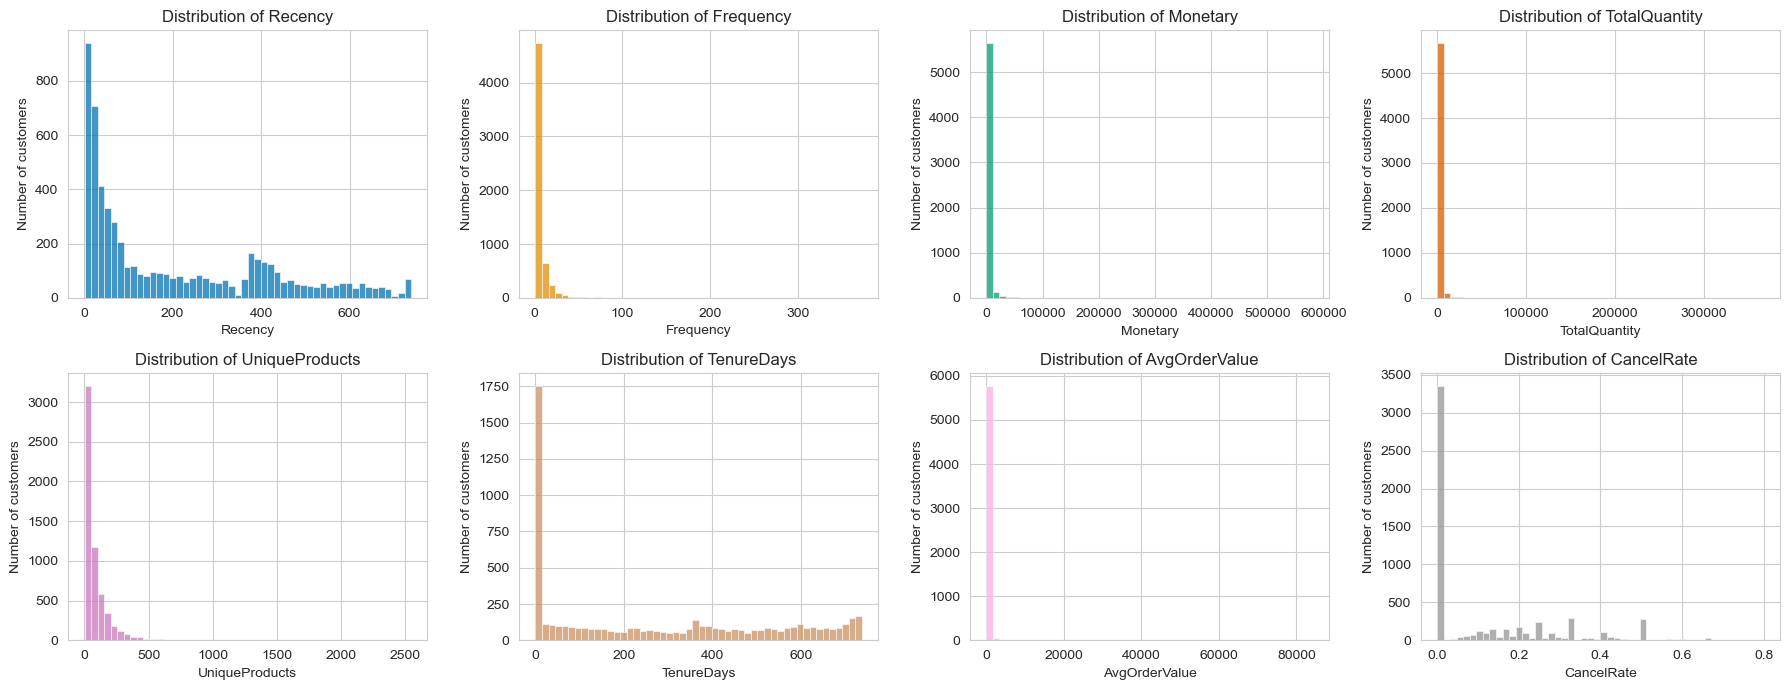

In [9]:
# --- Distribution of every feature (raw scale) ---
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col, colour in zip(axes.ravel(), eda_features, PALETTE):
    sns.histplot(customers[col], bins=50, kde=False, ax=ax, color=colour)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("Number of customers")
plt.tight_layout()
plt.savefig("eda_feature_distributions.png", bbox_inches="tight")
plt.show()


**Insight.** `Frequency`, `Monetary`, `TotalQuantity`, `UniqueProducts` and `AvgOrderValue` are all **extremely right-skewed**: most customers buy a few times for modest amounts, while a handful of very large (probably wholesale) customers spend orders of magnitude more. `Recency` is spread across the whole two-year window with a pile-up of recent buyers, and `CancelRate` is zero for most customers. Because K-Means and hierarchical clustering are distance-based, this skew would let a few extreme customers dominate — which motivates the **log-transform** in Section 6.


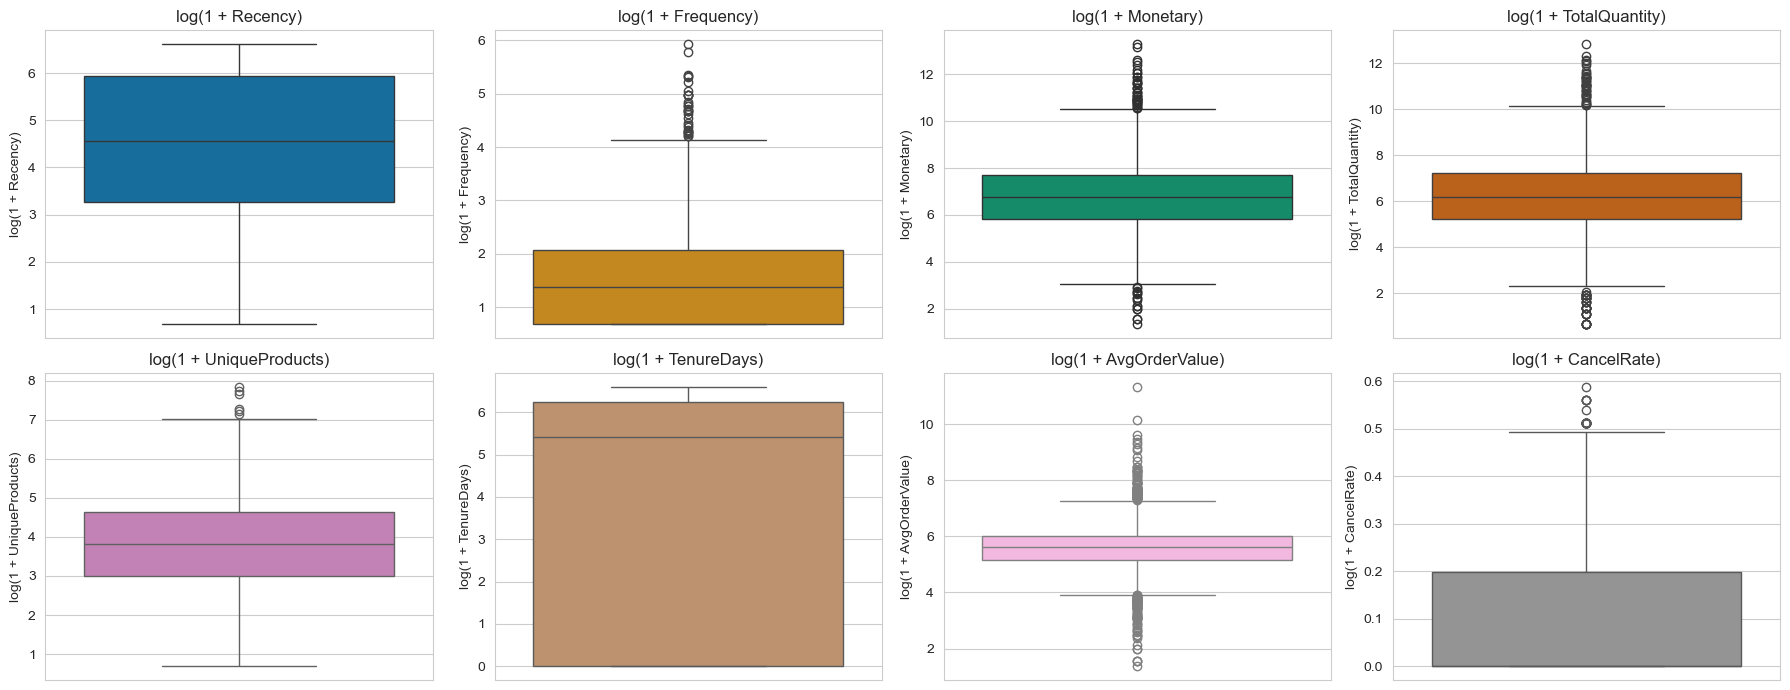

Outliers per feature (1.5 x IQR rule, raw scale):
Recency             0
Frequency         424
Monetary          619
TotalQuantity     603
UniqueProducts    451
TenureDays          0
AvgOrderValue     384
CancelRate         74
dtype: int64


In [10]:
# --- Boxplots: outlier check (on log scale so the box is visible) ---
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col, colour in zip(axes.ravel(), eda_features, PALETTE):
    sns.boxplot(y=np.log1p(customers[col]), ax=ax, color=colour)
    ax.set_title(f"log(1 + {col})")
    ax.set_ylabel(f"log(1 + {col})")
plt.tight_layout()
plt.savefig("eda_boxplots.png", bbox_inches="tight")
plt.show()

# Count outliers by the 1.5*IQR rule on the RAW scale
iqr_counts = {}
for col in eda_features:
    q1, q3 = customers[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_counts[col] = int(((customers[col] < q1 - 1.5 * iqr) | (customers[col] > q3 + 1.5 * iqr)).sum())
print("Outliers per feature (1.5 x IQR rule, raw scale):")
print(pd.Series(iqr_counts))


**Insight.** On the raw scale a large number of customers are flagged as outliers by the IQR rule for the spending-related features — but these are **real, legitimate customers** (big wholesale buyers), not data errors, so deleting them would remove an entire genuine segment. Instead we **treat** outliers in Section 6 by log-transforming and then clipping the extreme tails (winsorising), which keeps every customer but stops a few points from dominating distances.


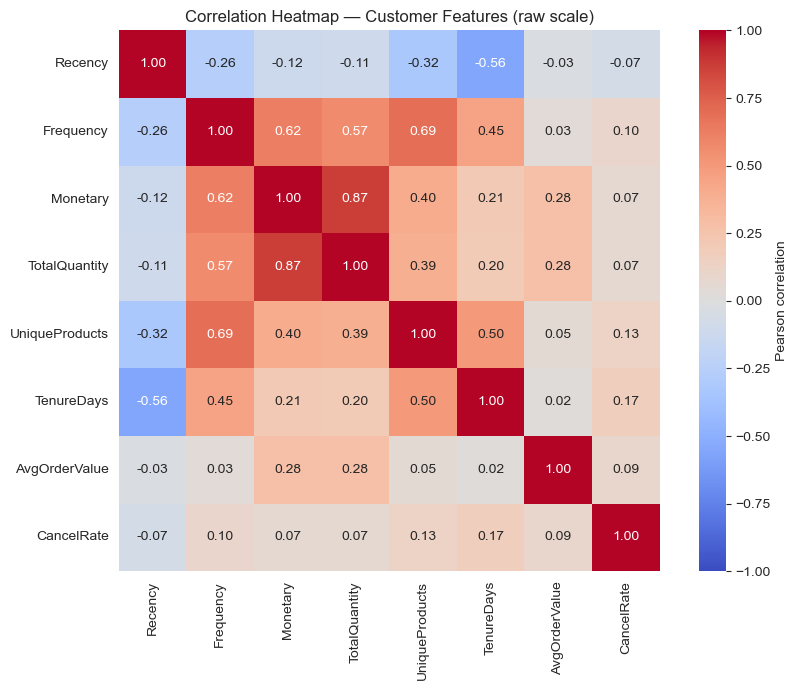

In [11]:
# --- Correlation heatmap ---
plt.figure(figsize=(9, 7))
corr = customers[eda_features].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1,
            square=True, cbar_kws={"label": "Pearson correlation"})
plt.title("Correlation Heatmap — Customer Features (raw scale)")
plt.tight_layout()
plt.savefig("eda_correlation_heatmap.png", bbox_inches="tight")
plt.show()


**Insight.** `Monetary` and `TotalQuantity` are almost perfectly correlated, and `Frequency`, `UniqueProducts` and `Monetary` are also strongly related (customers who order more often buy more distinct items and spend more). `Recency` correlates negatively with `TenureDays` and `Frequency` (recent customers tend to be long-standing, frequent ones). Including near-duplicate features would **double-count** the same signal in Euclidean distance, so `TotalQuantity` is **dropped** from the clustering feature set (it adds nothing beyond `Monetary`).


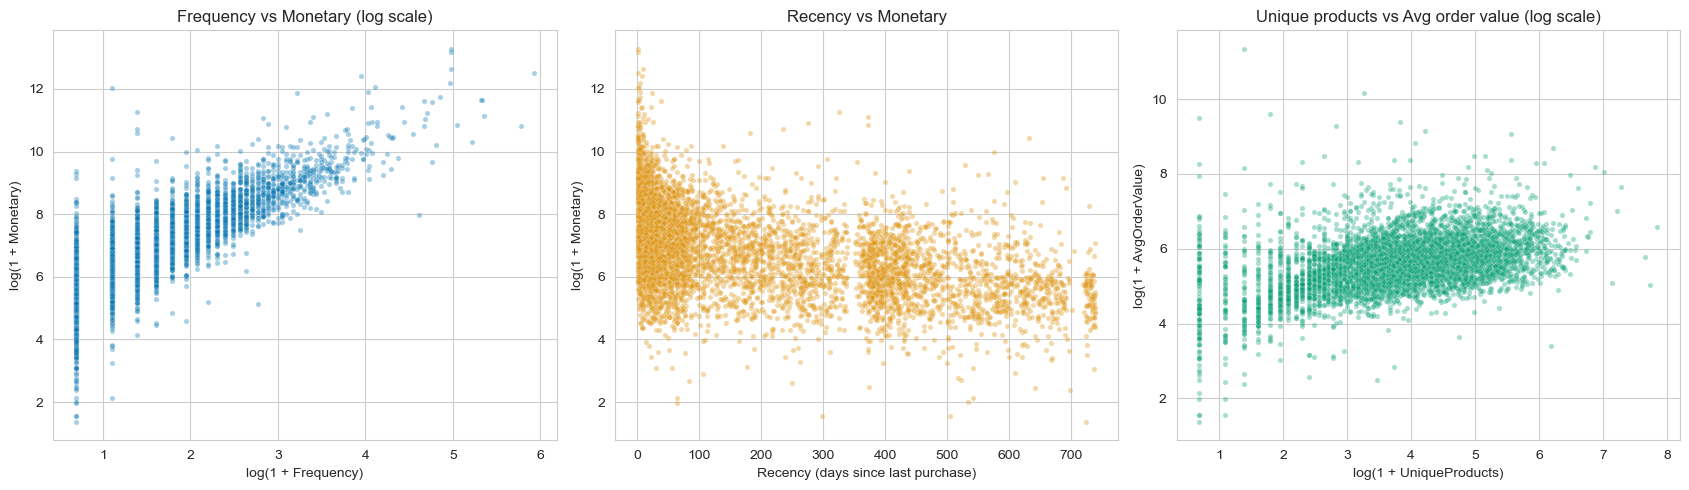

In [12]:
# --- Relationships between key features (log scale), a "target-like" look at structure ---
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.scatterplot(x=np.log1p(customers["Frequency"]), y=np.log1p(customers["Monetary"]),
                alpha=0.35, s=14, ax=axes[0], color=PALETTE[0])
axes[0].set_title("Frequency vs Monetary (log scale)")
axes[0].set_xlabel("log(1 + Frequency)")
axes[0].set_ylabel("log(1 + Monetary)")

sns.scatterplot(x=customers["Recency"], y=np.log1p(customers["Monetary"]),
                alpha=0.35, s=14, ax=axes[1], color=PALETTE[1])
axes[1].set_title("Recency vs Monetary")
axes[1].set_xlabel("Recency (days since last purchase)")
axes[1].set_ylabel("log(1 + Monetary)")

sns.scatterplot(x=np.log1p(customers["UniqueProducts"]), y=np.log1p(customers["AvgOrderValue"]),
                alpha=0.35, s=14, ax=axes[2], color=PALETTE[2])
axes[2].set_title("Unique products vs Avg order value (log scale)")
axes[2].set_xlabel("log(1 + UniqueProducts)")
axes[2].set_ylabel("log(1 + AvgOrderValue)")

plt.tight_layout()
plt.savefig("eda_feature_relationships.png", bbox_inches="tight")
plt.show()


**Insight.** On the log scale `Frequency` vs `Monetary` forms a clear upward band — more orders means more spend — with visible **density structure** (a dense mass of low-frequency customers and a thinner arm of heavy buyers), a good sign that natural groups exist. `Recency` vs `Monetary` shows that high spenders are concentrated among *recent* customers, while long-lapsed customers are almost all low spenders. The unstructured spread in the third plot shows that basket value and product breadth carry information that RFM alone does not.


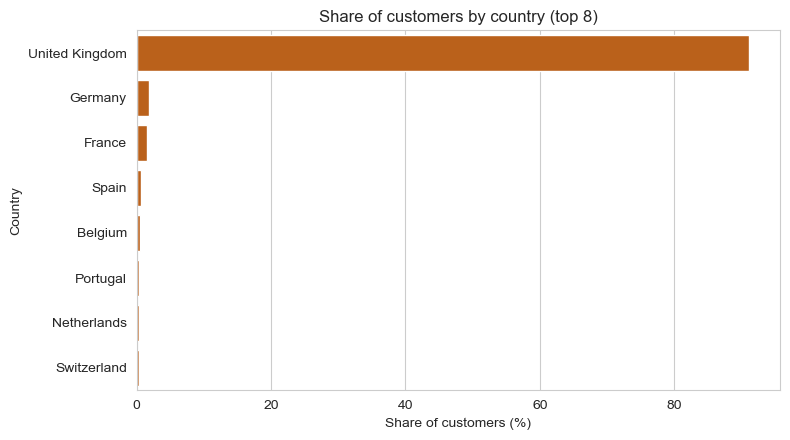

United Kingdom share: 91.1%


In [13]:
# --- Country mix (used later only to interpret clusters, never for fitting) ---
country_share = customers["Country"].value_counts(normalize=True).head(8) * 100

plt.figure(figsize=(8, 4.5))
sns.barplot(x=country_share.values, y=country_share.index, color=PALETTE[3])
plt.title("Share of customers by country (top 8)")
plt.xlabel("Share of customers (%)")
plt.ylabel("Country")
plt.tight_layout()
plt.savefig("eda_country_share.png", bbox_inches="tight")
plt.show()

print(f"United Kingdom share: {country_share['United Kingdom']:.1f}%")


**Insight.** The business is overwhelmingly **UK-based**; all other countries together are a small minority, so `Country` has too little variety to be a useful clustering feature. We keep it only as a **post-hoc interpretation variable** — the closest thing this dataset offers to "ground-truth" information — and check later whether the clusters differ in their country mix.


---
## 6. Preprocessing for Clustering

Clustering has no train/test split, so there is no leakage concern from fitting the scaler on all customers (there is no held-out data to leak into). Steps:

1. **Feature selection** — drop `TotalQuantity` (redundant with `Monetary`); `Country` is categorical and not used for fitting.
2. **Log-transform** (`log1p`) the skewed count/amount features to tame the long right tails.
3. **Winsorise** (clip) each feature at the 0.5th / 99.5th percentile to limit the remaining extreme points — outlier *treatment* without losing customers.
4. **Standardise** with `StandardScaler`, so every feature has mean 0 and std 1 — essential because K-Means and hierarchical clustering use Euclidean distance.


In [14]:
cluster_features = ["Recency", "Frequency", "Monetary", "AvgOrderValue",
                    "UniqueProducts", "TenureDays", "CancelRate"]

# 1) log-transform the skewed features (CancelRate is already bounded in [0, 1])
log_features = ["Recency", "Frequency", "Monetary", "AvgOrderValue", "UniqueProducts", "TenureDays"]
X_df = customers[cluster_features].copy()
X_df[log_features] = np.log1p(X_df[log_features])

# 2) winsorise at the 0.5th and 99.5th percentiles
lower, upper = X_df.quantile(0.005), X_df.quantile(0.995)
X_df = X_df.clip(lower=lower, upper=upper, axis=1)

# 3) standardise
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_df)

print("Clustering matrix shape:", X_scaled.shape)
print("Feature means (should be ~0):", np.round(X_scaled.mean(axis=0), 3))
print("Feature stds  (should be ~1):", np.round(X_scaled.std(axis=0), 3))


Clustering matrix shape: (5852, 7)
Feature means (should be ~0): [-0.  0.  0. -0. -0.  0.  0.]
Feature stds  (should be ~1): [1. 1. 1. 1. 1. 1. 1.]


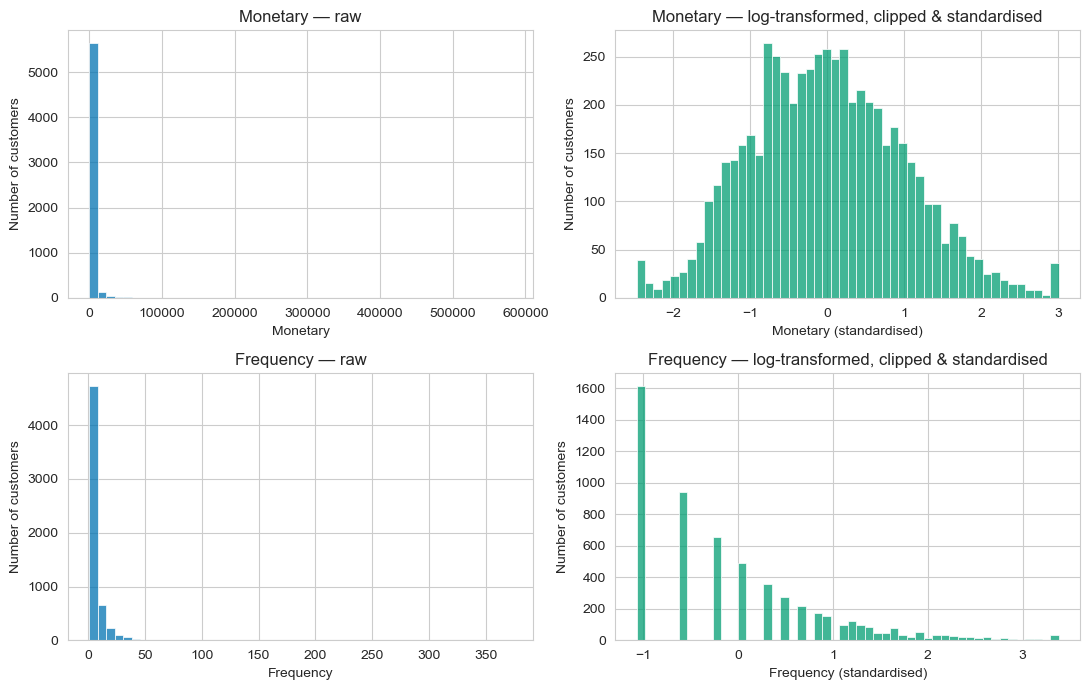

In [15]:
# Visual check: distributions before vs after preprocessing for two skewed features
fig, axes = plt.subplots(2, 2, figsize=(11, 7))
for row, col in enumerate(["Monetary", "Frequency"]):
    sns.histplot(customers[col], bins=50, ax=axes[row, 0], color=PALETTE[0])
    axes[row, 0].set_title(f"{col} — raw")
    axes[row, 0].set_xlabel(col)
    axes[row, 0].set_ylabel("Number of customers")
    sns.histplot(X_scaled[:, cluster_features.index(col)], bins=50, ax=axes[row, 1], color=PALETTE[2])
    axes[row, 1].set_title(f"{col} — log-transformed, clipped & standardised")
    axes[row, 1].set_xlabel(f"{col} (standardised)")
    axes[row, 1].set_ylabel("Number of customers")
plt.tight_layout()
plt.savefig("preprocessing_before_after.png", bbox_inches="tight")
plt.show()


**Insight.** The long right tail is gone: after log-transform, clipping and scaling the features are roughly bell-shaped on a common scale, so no single feature (or a handful of whales) will dominate the distance calculations.


---
## 7. Algorithm 1 — K-Means Clustering

### 7.1 Choosing *k*: Elbow curve (+ silhouette sweep)
The **elbow curve** plots inertia (within-cluster sum of squares) against *k*; the "elbow" where the improvement flattens suggests a good *k*. Because the elbow is often ambiguous, we also plot the **silhouette score** for each *k* as a second opinion.


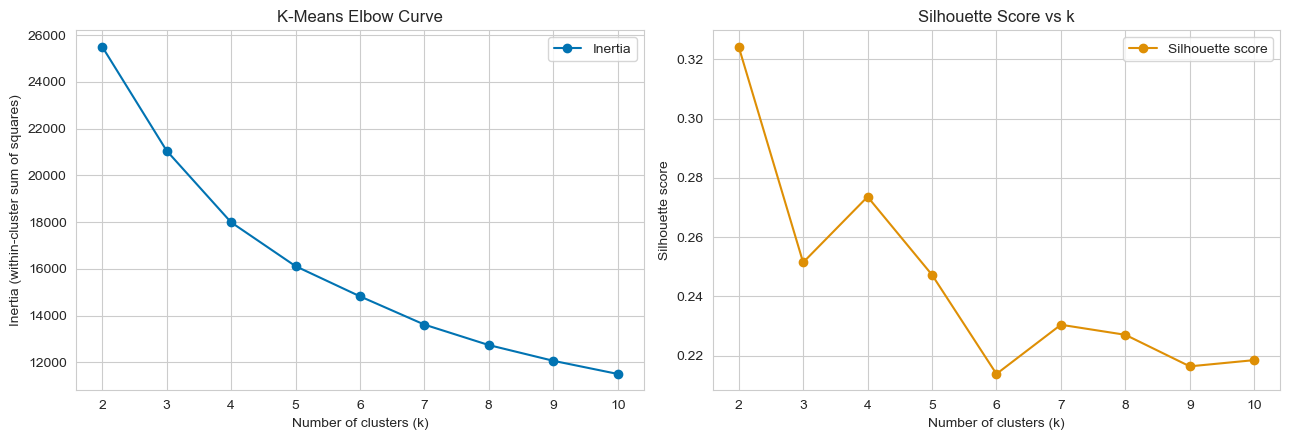

 k    Inertia  Silhouette
 2 25,504.657       0.324
 3 21,055.751       0.251
 4 17,994.599       0.274
 5 16,120.064       0.247
 6 14,829.010       0.214
 7 13,619.896       0.230
 8 12,744.705       0.227
 9 12,072.344       0.216
10 11,509.962       0.219


In [16]:
k_range = range(2, 11)
inertias, sil_scores = [], []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
    labels_k = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels_k))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].plot(list(k_range), inertias, "o-", color=PALETTE[0], label="Inertia")
axes[0].set_title("K-Means Elbow Curve")
axes[0].set_xlabel("Number of clusters (k)")
axes[0].set_ylabel("Inertia (within-cluster sum of squares)")
axes[0].legend()

axes[1].plot(list(k_range), sil_scores, "o-", color=PALETTE[1], label="Silhouette score")
axes[1].set_title("Silhouette Score vs k")
axes[1].set_xlabel("Number of clusters (k)")
axes[1].set_ylabel("Silhouette score")
axes[1].legend()

plt.tight_layout()
plt.savefig("kmeans_elbow_silhouette.png", bbox_inches="tight")
plt.show()

print(pd.DataFrame({"k": list(k_range), "Inertia": inertias, "Silhouette": sil_scores}).to_string(index=False))


**Choosing k.** The inertia curve falls smoothly with no sharp kink — typical of real customer data, where behaviour is a continuum rather than a set of isolated blobs — but it visibly bends around **k = 4–5**. The silhouette sweep gives a second opinion: it is highest at *k* = 2 (about 0.32), but that solution only splits "active" from "lapsed" customers, which is too coarse to act on. Among *k* ≥ 3, **k = 4 is a local silhouette peak** (higher than both *k* = 3 and *k* = 5). We therefore choose **k = 4**: it sits at the bend of the elbow, is the best-scoring option beyond the trivial 2-way split, and (as shown in Section 11) produces business-meaningful segments. The hierarchical dendrogram below independently points to the same number.

In [17]:
# Final K-Means model
K_FINAL = 4   # chosen from the elbow + silhouette analysis above (see commentary)

kmeans = KMeans(n_clusters=K_FINAL, n_init=10, random_state=RANDOM_STATE)
labels_kmeans = kmeans.fit_predict(X_scaled)

print("K-Means cluster sizes:")
print(pd.Series(labels_kmeans).value_counts().sort_index())


K-Means cluster sizes:
0    1596
1    1475
2     877
3    1904
Name: count, dtype: int64


---
## 8. Algorithm 2 — Agglomerative Hierarchical Clustering

### 8.1 Dendrogram
A dendrogram shows how clusters merge bottom-up; a tall vertical jump means two quite different clusters were merged, so cutting just below the biggest jump gives a natural number of clusters. We use **Ward linkage** (minimises the increase in within-cluster variance) and truncate the tree to the last 30 merges for readability.


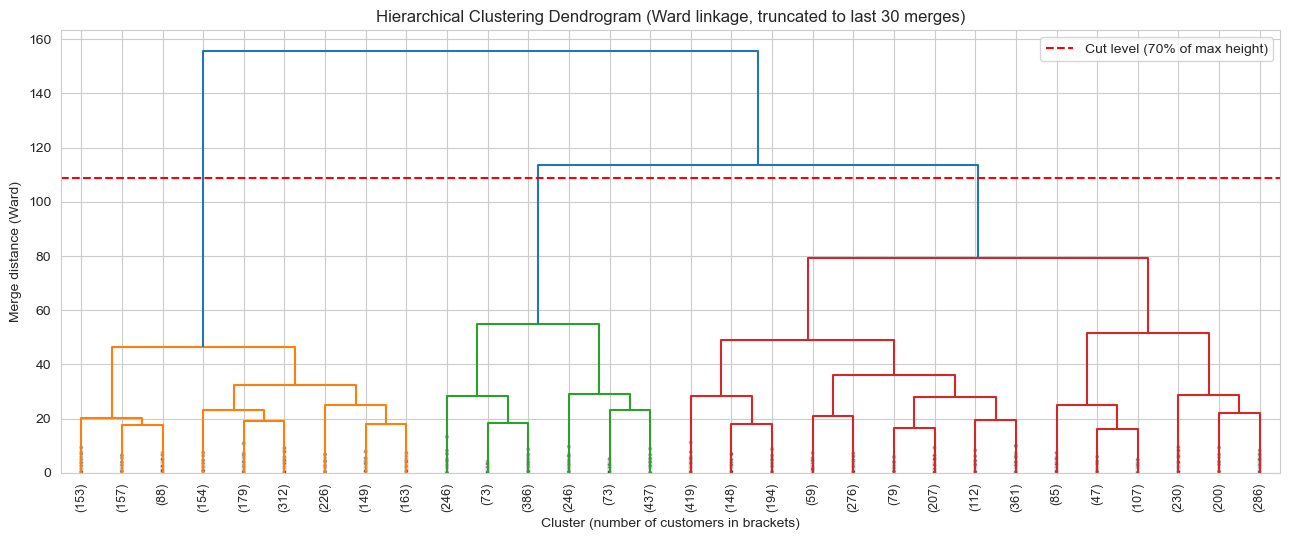

Last 10 merge heights: [ 29.1  32.6  36.3  46.3  49.1  51.7  55.1  79.1 113.5 155.4]
Jumps between consecutive merges: [ 3.5  3.7 10.1  2.8  2.5  3.4 24.1 34.3 42. ]


In [18]:
Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(13, 5.5))
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90., leaf_font_size=9,
           show_contracted=True, color_threshold=0.7 * Z[-1, 2])
plt.title("Hierarchical Clustering Dendrogram (Ward linkage, truncated to last 30 merges)")
plt.xlabel("Cluster (number of customers in brackets)")
plt.ylabel("Merge distance (Ward)")
plt.axhline(y=0.7 * Z[-1, 2], color="red", linestyle="--", label="Cut level (70% of max height)")
plt.legend()
plt.tight_layout()
plt.savefig("hierarchical_dendrogram.png", bbox_inches="tight")
plt.show()

# Largest jumps in merge height (last 10 merges) -> where a cut is most natural
heights = Z[-10:, 2]
print("Last 10 merge heights:", np.round(heights, 1))
print("Jumps between consecutive merges:", np.round(np.diff(heights), 1))


**Reading the dendrogram.** The merge heights climb slowly for most of the tree and then jump sharply in the **last few merges** (the three biggest jumps are in the final merges). Cutting just below the jump that follows the 4-cluster level (the red dashed line) leaves **4 clusters** — the same *k* suggested by the K-Means silhouette/elbow analysis, so the two algorithms agree on a sensible number of segments.

### 8.2 Comparing linkage strategies
Linkage defines the distance between two clusters. We compare four strategies at the same number of clusters (*k* = `K_FINAL`) using the three metrics:
- **ward** — minimise variance increase (tends to give compact, similarly-sized clusters)
- **complete** — maximum pairwise distance (compact clusters, sensitive to outliers)
- **average** — mean pairwise distance (compromise)
- **single** — minimum pairwise distance (can "chain" together, often one giant cluster)


In [19]:
linkage_results, linkage_labels = [], {}

for method in ["ward", "complete", "average", "single"]:
    agg = AgglomerativeClustering(n_clusters=K_FINAL, linkage=method)
    lab = agg.fit_predict(X_scaled)
    linkage_labels[method] = lab
    linkage_results.append(evaluate_clustering(X_scaled, lab, f"Agglomerative ({method})"))

linkage_df = pd.DataFrame(linkage_results).set_index("Algorithm")
linkage_df


,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster,Largest cluster
Algorithm,,,,,,
Agglomerative (ward),4,0.244,1.436,"2,184.726",955,1855
Agglomerative (complete),4,0.023,2.430,847.062,490,3426
Agglomerative (average),4,0.234,0.983,118.470,1,5723
Agglomerative (single),4,0.312,0.443,4.722,1,5849


**Which linkage?** Read the scores *together with the cluster sizes*:
- **Single** linkage has the best-looking Silhouette and Davies-Bouldin, but one cluster holds almost every customer and the others contain a single customer each — the classic *chaining* effect. Its Calinski-Harabasz is tiny. This is a **degenerate partition**: the scores look good only because the singletons are trivially "far" from everything.
- **Average** linkage has the same problem (a cluster of size 1).
- **Complete** linkage is dragged around by outliers and has a near-zero Silhouette.
- **Ward** linkage produces **balanced, usable clusters** and by far the best Calinski-Harabasz among the hierarchical options, so it is selected as the final hierarchical model.

Lesson for the viva: an internal metric alone can be misleading — always check cluster sizes.

In [21]:
# Final hierarchical model = best linkage by silhouette among sensible (non-degenerate) options
BEST_LINKAGE = "ward"   # see commentary above
labels_agg = linkage_labels[BEST_LINKAGE]

print(f"Final Agglomerative model: linkage = {BEST_LINKAGE}, k = {K_FINAL}")
print(pd.Series(labels_agg).value_counts().sort_index())


Final Agglomerative model: linkage = ward, k = 4
0    1461
1    1855
2     955
3    1581
Name: count, dtype: int64


---
## 9. Evaluation Metrics — Consolidated Table

All three mandatory internal metrics for every algorithm / configuration (rubric B2):

| Metric | Direction | Meaning |
|---|---|---|
| Silhouette Score | higher ↑ | How well each point fits its own cluster vs. the nearest other cluster (-1 … 1) |
| Davies-Bouldin Index | **lower ↓** | Average similarity between each cluster and its most similar one |
| Calinski-Harabasz Index | higher ↑ | Ratio of between-cluster to within-cluster dispersion |


In [22]:
metrics_rows = [
    evaluate_clustering(X_scaled, labels_kmeans, f"K-Means (k={K_FINAL})"),
    evaluate_clustering(X_scaled, labels_agg, f"Agglomerative ({BEST_LINKAGE}, k={K_FINAL})"),
]
# also include the other linkage options for completeness
for method in ["complete", "average", "single"]:
    if method != BEST_LINKAGE:
        metrics_rows.append(evaluate_clustering(X_scaled, linkage_labels[method], f"Agglomerative ({method}, k={K_FINAL})"))

metrics_df = pd.DataFrame(metrics_rows).set_index("Algorithm")
metrics_df.sort_values("Silhouette", ascending=False)


,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Smallest cluster,Largest cluster
Algorithm,,,,,,
"Agglomerative (single, k=4)",4,0.312,0.443,4.722,1,5849
K-Means (k=4),4,0.274,1.290,"2,488.250",877,1904
"Agglomerative (ward, k=4)",4,0.244,1.436,"2,184.726",955,1855
"Agglomerative (average, k=4)",4,0.234,0.983,118.470,1,5723
"Agglomerative (complete, k=4)",4,0.023,2.430,847.062,490,3426


In [23]:
# Agreement between the two main algorithms (Adjusted Rand Index: 1 = identical partitions, ~0 = random)
ari = adjusted_rand_score(labels_kmeans, labels_agg)
print(f"Adjusted Rand Index between K-Means and Agglomerative ({BEST_LINKAGE}): {ari:.3f}")


Adjusted Rand Index between K-Means and Agglomerative (ward): 0.674


**Interpreting the metrics.**
- **K-Means (k=4)** edges out **Ward** on all three metrics (higher Silhouette, lower Davies-Bouldin, higher Calinski-Harabasz). K-Means directly minimises within-cluster variance, which is exactly what these metrics reward, so this is expected.
- The rows for single/average linkage should be ignored despite some good-looking numbers: their size columns show degenerate partitions (see Section 8.2).
- A Silhouette of roughly 0.25–0.3 indicates **weak-to-moderate structure**: clusters are distinguishable but touch/overlap. That is realistic for customer behaviour, which changes gradually rather than in sharp jumps.
- The Adjusted Rand Index (~0.67) shows the two algorithms find **broadly similar but not identical** groupings — evidence that the segments are real and not an artefact of one method.

**Conclusion of the comparison:** K-Means (k=4) is the best-performing algorithm; Ward agglomerative is a close, balanced alternative.